# Six-feature tennis model retraining

Train the existing six classifier families on one explicit six-column feature contract. Use 2015–2024 for training, 2025 for validation, and 2026 as the untouched holdout. After recording holdout metrics, refit final research models on all completed matches. All outputs remain under `research/`.

In [1]:
from pathlib import Path
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

RANDOM_SEED = 42
WORKING_DIR = Path.cwd().resolve()
RESEARCH_DIR = WORKING_DIR if WORKING_DIR.name == "research" else WORKING_DIR / "research"
if not RESEARCH_DIR.is_dir():
    raise FileNotFoundError(
        "Run this notebook from the project root or the research directory."
    )

DATA_DIR = RESEARCH_DIR / "data" / "output"
SPLIT_PATHS = {
    "Train": DATA_DIR / "model_train_2015_2024.csv",
    "Validation": DATA_DIR / "model_validation_2025.csv",
    "Holdout": DATA_DIR / "model_test_2026.csv",
}
MODEL_FEATURE_COLUMNS = [
    "GlobalEloDiff",
    "SurfaceEloDiff",
    "RankDiff",
    "Player1LayoffOver6Months",
    "Player2LayoffOver6Months",
    "MatchesLast7DaysDiff",
]
ODDS_COLUMNS = [
    "B365Player1Odds",
    "B365Player2Odds",
    "PSPlayer1Odds",
    "PSPlayer2Odds",
]
TARGET_COLUMN = "Player1Won"
EXPECTED_COLUMNS = ["Date", *MODEL_FEATURE_COLUMNS, *ODDS_COLUMNS, TARGET_COLUMN]

assert len(MODEL_FEATURE_COLUMNS) == 6
assert len(set(MODEL_FEATURE_COLUMNS)) == 6

datasets = {
    split_name: pd.read_csv(path, parse_dates=["Date"], low_memory=False)
    for split_name, path in SPLIT_PATHS.items()
}
for split_name, frame in datasets.items():
    assert frame.columns.tolist() == EXPECTED_COLUMNS
    assert not frame.empty
    assert frame["Date"].is_monotonic_increasing
    print(
        f"{split_name}: {len(frame):,} rows, "
        f"{frame['Date'].min():%Y-%m-%d} to {frame['Date'].max():%Y-%m-%d}"
    )

datasets["Train"].head()

Train: 24,112 rows, 2015-01-05 to 2024-12-31
Validation: 2,491 rows, 2025-01-01 to 2025-11-16
Holdout: 1,822 rows, 2026-01-04 to 2026-08-14


,Date,GlobalEloDiff,SurfaceEloDiff,RankDiff,Player1LayoffOver6Months,Player2LayoffOver6Months,MatchesLast7DaysDiff,B365Player1Odds,B365Player2Odds,PSPlayer1Odds,PSPlayer2Odds,Player1Won
0,2015-01-05,0.0,0.0,104.0,NaN,NaN,0,4.50,1.18,4.67,1.23,1
1,2015-01-05,0.0,0.0,-124.0,NaN,NaN,0,1.44,2.62,1.53,2.67,0
2,2015-01-05,0.0,0.0,-41.0,NaN,NaN,0,1.28,3.50,1.34,3.50,1
3,2015-01-05,0.0,0.0,-18.0,NaN,NaN,0,2.25,1.57,2.37,1.65,0
4,2015-01-05,0.0,0.0,-70.0,NaN,NaN,0,1.66,2.10,1.81,2.10,1


## Fixed preprocessing and model definitions

All six model inputs are numeric. Median imputation is fitted inside each pipeline; scaling is used only for logistic regression and the MLP. Date, target, and bookmaker odds are never passed to a model.

In [2]:
LAYOFF_COLUMNS = ["Player1LayoffOver6Months", "Player2LayoffOver6Months"]

for split_name, frame in datasets.items():
    frame = frame.copy()
    for column in LAYOFF_COLUMNS:
        frame[column] = (
            frame[column]
            .astype("string")
            .map({"True": 1.0, "False": 0.0})
            .astype(float)
        )
    for column in MODEL_FEATURE_COLUMNS:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    frame[TARGET_COLUMN] = pd.to_numeric(
        frame[TARGET_COLUMN], errors="raise"
    ).astype("int8")
    assert set(frame[TARGET_COLUMN].unique()).issubset({0, 1})
    datasets[split_name] = frame

feature_columns = list(MODEL_FEATURE_COLUMNS)
X_train = datasets["Train"][feature_columns].copy()
y_train = datasets["Train"][TARGET_COLUMN].copy()
X_validation = datasets["Validation"][feature_columns].copy()
y_validation = datasets["Validation"][TARGET_COLUMN].copy()
X_holdout = datasets["Holdout"][feature_columns].copy()
y_holdout = datasets["Holdout"][TARGET_COLUMN].copy()

assert len(feature_columns) == 6
assert not set(ODDS_COLUMNS).intersection(feature_columns)
assert "Date" not in feature_columns and TARGET_COLUMN not in feature_columns
assert X_train.columns.tolist() == feature_columns
assert X_validation.columns.tolist() == feature_columns
assert X_holdout.columns.tolist() == feature_columns
assert datasets["Train"]["Date"].max() < datasets["Validation"]["Date"].min()
assert datasets["Validation"]["Date"].max() < datasets["Holdout"]["Date"].min()


def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer(
        [("numeric", Pipeline(numeric_steps), feature_columns)],
        remainder="drop",
        verbose_feature_names_out=False,
    )


MODEL_FACTORIES = {
    "Decision Tree": lambda: DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=30,
        random_state=RANDOM_SEED,
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=300,
        max_depth=14,
        min_samples_leaf=8,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_SEED,
    ),
    "XGBoost": lambda: XGBClassifier(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_SEED,
    ),
    "LightGBM": lambda: LGBMClassifier(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=30,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        verbosity=-1,
        n_jobs=-1,
        random_state=RANDOM_SEED,
    ),
    "Logistic Regression": lambda: LogisticRegression(
        C=1.0,
        solver="saga",
        max_iter=2_000,
        n_jobs=-1,
        random_state=RANDOM_SEED,
    ),
    "Simple Neural Net": lambda: MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=150,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=12,
        random_state=RANDOM_SEED,
    ),
}
SCALED_MODELS = {"Logistic Regression", "Simple Neural Net"}


def build_model_pipeline(model_name: str) -> Pipeline:
    return Pipeline(
        [
            ("preprocessor", make_preprocessor(model_name in SCALED_MODELS)),
            ("model", MODEL_FACTORIES[model_name]()),
        ]
    )


def validate_probabilities(probabilities: np.ndarray, expected_rows: int) -> None:
    assert probabilities.shape == (expected_rows,)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0.0) & (probabilities <= 1.0)).all()


def positive_probability(pipeline: Pipeline, features: pd.DataFrame) -> np.ndarray:
    classes = np.asarray(pipeline.classes_)
    positive_indices = np.flatnonzero(classes == 1)
    assert len(positive_indices) == 1, f"Unexpected classes: {classes}"
    probabilities = np.asarray(pipeline.predict_proba(features))[
        :, int(positive_indices[0])
    ]
    validate_probabilities(probabilities, len(features))
    return probabilities


print(f"Model features ({len(feature_columns)}): {feature_columns}")
print("Models:", ", ".join(MODEL_FACTORIES))

Model features (6): ['GlobalEloDiff', 'SurfaceEloDiff', 'RankDiff', 'Player1LayoffOver6Months', 'Player2LayoffOver6Months', 'MatchesLast7DaysDiff']
Models: Decision Tree, Random Forest, XGBoost, LightGBM, Logistic Regression, Simple Neural Net


## 2025 validation and untouched 2026 holdout

Fit on 2015–2024 for validation. Then refit unchanged configurations through 2025 and evaluate each exactly once on 2026. The holdout pipelines are retained for feature importance.

In [3]:
validation_predictions = {}
validation_pipelines = {}
score_rows = []

for model_name in MODEL_FACTORIES:
    started_at = time.perf_counter()
    pipeline = build_model_pipeline(model_name)
    pipeline.fit(X_train, y_train)
    assert list(pipeline.feature_names_in_) == feature_columns
    probabilities = positive_probability(pipeline, X_validation)
    elapsed_seconds = time.perf_counter() - started_at

    validation_predictions[model_name] = probabilities
    validation_pipelines[model_name] = pipeline
    score_rows.append(
        {
            "Split": "Validation 2025",
            "Method": model_name,
            "BrierScore": brier_score_loss(y_validation, probabilities),
            "LogLoss": log_loss(y_validation, probabilities, labels=[0, 1]),
            "Rows": len(y_validation),
            "FitSeconds": elapsed_seconds,
        }
    )
    print(
        f"Validation {model_name}: Brier={score_rows[-1]['BrierScore']:.5f}, "
        f"LogLoss={score_rows[-1]['LogLoss']:.5f} ({elapsed_seconds:.1f}s)"
    )

train_validation = pd.concat(
    [datasets["Train"], datasets["Validation"]],
    ignore_index=True,
)
X_train_validation = train_validation[feature_columns].copy()
y_train_validation = train_validation[TARGET_COLUMN].astype("int8")

holdout_predictions = {}
evaluation_pipelines = {}
for model_name in MODEL_FACTORIES:
    started_at = time.perf_counter()
    pipeline = build_model_pipeline(model_name)
    pipeline.fit(X_train_validation, y_train_validation)
    assert list(pipeline.feature_names_in_) == feature_columns
    probabilities = positive_probability(pipeline, X_holdout)
    elapsed_seconds = time.perf_counter() - started_at

    holdout_predictions[model_name] = probabilities
    evaluation_pipelines[model_name] = pipeline
    score_rows.append(
        {
            "Split": "Holdout 2026",
            "Method": model_name,
            "BrierScore": brier_score_loss(y_holdout, probabilities),
            "LogLoss": log_loss(y_holdout, probabilities, labels=[0, 1]),
            "Rows": len(y_holdout),
            "FitSeconds": elapsed_seconds,
        }
    )
    print(
        f"Holdout {model_name}: Brier={score_rows[-1]['BrierScore']:.5f}, "
        f"LogLoss={score_rows[-1]['LogLoss']:.5f} ({elapsed_seconds:.1f}s)"
    )

model_score_results = pd.DataFrame(score_rows)
assert set(MODEL_FACTORIES) == set(validation_predictions)
assert set(MODEL_FACTORIES) == set(holdout_predictions)
assert set(MODEL_FACTORIES) == set(evaluation_pipelines)
model_score_results.sort_values(["Split", "BrierScore"])

Validation Decision Tree: Brier=0.22118, LogLoss=0.66229 (0.0s)


Validation Random Forest: Brier=0.21781, LogLoss=0.62544 (1.0s)


Validation XGBoost: Brier=0.21561, LogLoss=0.62044 (0.4s)


/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation LightGBM: Brier=0.21812, LogLoss=0.62741 (1.6s)
Validation Logistic Regression: Brier=0.21516, LogLoss=0.61785 (0.0s)


Validation Simple Neural Net: Brier=0.21702, LogLoss=0.62173 (2.8s)
Holdout Decision Tree: Brier=0.22555, LogLoss=0.70128 (0.1s)


... (2 outputs left out)

/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Holdout LightGBM: Brier=0.21755, LogLoss=0.62429 (1.6s)
Holdout Logistic Regression: Brier=0.21535, LogLoss=0.61807 (0.0s)


Holdout Simple Neural Net: Brier=0.21462, LogLoss=0.61675 (2.4s)


,Split,Method,BrierScore,LogLoss,Rows,FitSeconds
11,Holdout 2026,Simple Neural Net,0.214618,0.616750,1822,2.411377
10,Holdout 2026,Logistic Regression,0.215355,0.618070,1822,0.035944
8,Holdout 2026,XGBoost,0.216206,0.620670,1822,0.361475
7,Holdout 2026,Random Forest,0.217335,0.623148,1822,0.934227
9,Holdout 2026,LightGBM,0.217552,0.624291,1822,1.614834
6,Holdout 2026,Decision Tree,0.225548,0.701279,1822,0.074728
4,Validation 2025,Logistic Regression,0.215162,0.617846,2491,0.036319
2,Validation 2025,XGBoost,0.215613,0.620439,2491,0.361978
5,Validation 2025,Simple Neural Net,0.217016,0.621727,2491,2.770652
1,Validation 2025,Random Forest,0.217809,0.625443,2491,0.963659


## Probability baselines

Compare model probabilities with a constant baseline and Elo probabilities reconstructed from the retained Elo differences. Bookmaker prices remain evaluation-only and are normalized to remove overround on rows where both sides are available.

In [4]:
ELO_SCALE = 400.0


def elo_probability_from_difference(difference: pd.Series) -> np.ndarray:
    numeric = pd.to_numeric(difference, errors="coerce")
    return (1.0 / (1.0 + 10.0 ** (-numeric / ELO_SCALE))).to_numpy(dtype=float)


def full_range_baselines(frame: pd.DataFrame) -> dict[str, np.ndarray]:
    global_elo = elo_probability_from_difference(frame["GlobalEloDiff"])
    surface_difference = frame["SurfaceEloDiff"].fillna(frame["GlobalEloDiff"])
    return {
        "Constant 0.5": np.full(len(frame), 0.5),
        "Global Elo": global_elo,
        "Surface Elo": elo_probability_from_difference(surface_difference),
    }


for split_name, frame, target in (
    ("Validation 2025", datasets["Validation"], y_validation),
    ("Holdout 2026", datasets["Holdout"], y_holdout),
):
    for method_name, probabilities in full_range_baselines(frame).items():
        validate_probabilities(probabilities, len(target))
        score_rows.append(
            {
                "Split": split_name,
                "Method": method_name,
                "BrierScore": brier_score_loss(target, probabilities),
                "LogLoss": log_loss(target, probabilities, labels=[0, 1]),
                "Rows": len(target),
                "FitSeconds": np.nan,
            }
        )


def normalized_bookmaker_probability(
    frame: pd.DataFrame,
    player1_odds_column: str,
    player2_odds_column: str,
) -> tuple[np.ndarray, np.ndarray]:
    player1_odds = pd.to_numeric(frame[player1_odds_column], errors="coerce")
    player2_odds = pd.to_numeric(frame[player2_odds_column], errors="coerce")
    available = (
        player1_odds.notna()
        & player2_odds.notna()
        & player1_odds.gt(1.0)
        & player2_odds.gt(1.0)
    )
    player1_implied = 1.0 / player1_odds.loc[available]
    player2_implied = 1.0 / player2_odds.loc[available]
    normalized = player1_implied / (player1_implied + player2_implied)
    return normalized.to_numpy(dtype=float), available.to_numpy()


odds_benchmark_rows = []
for split_name, frame, target, model_predictions in (
    ("Validation 2025", datasets["Validation"], y_validation, validation_predictions),
    ("Holdout 2026", datasets["Holdout"], y_holdout, holdout_predictions),
):
    for bookmaker, player1_column, player2_column in (
        ("B365", "B365Player1Odds", "B365Player2Odds"),
        ("PS", "PSPlayer1Odds", "PSPlayer2Odds"),
    ):
        bookmaker_probabilities, available = normalized_bookmaker_probability(
            frame, player1_column, player2_column
        )
        subset_target = target.to_numpy()[available]
        validate_probabilities(bookmaker_probabilities, len(subset_target))
        odds_benchmark_rows.append(
            {
                "Split": split_name,
                "OddsSubset": bookmaker,
                "Method": f"{bookmaker} normalized odds",
                "BrierScore": brier_score_loss(subset_target, bookmaker_probabilities),
                "LogLoss": log_loss(
                    subset_target, bookmaker_probabilities, labels=[0, 1]
                ),
                "Rows": len(subset_target),
            }
        )
        for model_name, probabilities in model_predictions.items():
            subset_probabilities = probabilities[available]
            odds_benchmark_rows.append(
                {
                    "Split": split_name,
                    "OddsSubset": bookmaker,
                    "Method": model_name,
                    "BrierScore": brier_score_loss(
                        subset_target, subset_probabilities
                    ),
                    "LogLoss": log_loss(
                        subset_target, subset_probabilities, labels=[0, 1]
                    ),
                    "Rows": len(subset_target),
                }
            )

score_results = (
    pd.DataFrame(score_rows)
    .sort_values(["Split", "BrierScore"])
    .reset_index(drop=True)
)
odds_benchmark_results = (
    pd.DataFrame(odds_benchmark_rows)
    .sort_values(["Split", "OddsSubset", "BrierScore"])
    .reset_index(drop=True)
)
assert score_results["BrierScore"].between(0.0, 1.0).all()
assert score_results["LogLoss"].ge(0.0).all()
assert odds_benchmark_results["BrierScore"].between(0.0, 1.0).all()
assert odds_benchmark_results["LogLoss"].ge(0.0).all()
display(score_results)
display(odds_benchmark_results)

,Split,Method,BrierScore,LogLoss,Rows,FitSeconds
0,Holdout 2026,Simple Neural Net,0.214618,0.616750,1822,2.411377
1,Holdout 2026,Logistic Regression,0.215355,0.618070,1822,0.035944
2,Holdout 2026,XGBoost,0.216206,0.620670,1822,0.361475
3,Holdout 2026,Random Forest,0.217335,0.623148,1822,0.934227
4,Holdout 2026,LightGBM,0.217552,0.624291,1822,1.614834
5,Holdout 2026,Global Elo,0.221309,0.633260,1822,NaN
6,Holdout 2026,Surface Elo,0.221921,0.633262,1822,NaN
7,Holdout 2026,Decision Tree,0.225548,0.701279,1822,0.074728
8,Holdout 2026,Constant 0.5,0.250000,0.693147,1822,NaN
9,Validation 2025,Logistic Regression,0.215162,0.617846,2491,0.036319


,Split,OddsSubset,Method,BrierScore,LogLoss,Rows
0,Holdout 2026,B365,B365 normalized odds,0.204312,0.593837,1806
1,Holdout 2026,B365,Simple Neural Net,0.215232,0.618549,1806
2,Holdout 2026,B365,Logistic Regression,0.215964,0.619832,1806
3,Holdout 2026,B365,XGBoost,0.216814,0.622312,1806
4,Holdout 2026,B365,Random Forest,0.217953,0.624810,1806
5,Holdout 2026,B365,LightGBM,0.218225,0.626195,1806
6,Holdout 2026,B365,Decision Tree,0.226178,0.703647,1806
7,Holdout 2026,PS,PS normalized odds,0.205203,0.597321,69
8,Holdout 2026,PS,Simple Neural Net,0.236772,0.669637,69
9,Holdout 2026,PS,Logistic Regression,0.239389,0.675216,69


## Score comparison and research model export

Chart complete-period scores, persist the 2015–2025 evaluation pipelines used for the 2026 holdout under `research/models/holdout_2026`, then fit fresh final pipelines on all 2015–2026 rows under `research/models`. The manifest keeps holdout metrics separate from the final all-data training range.

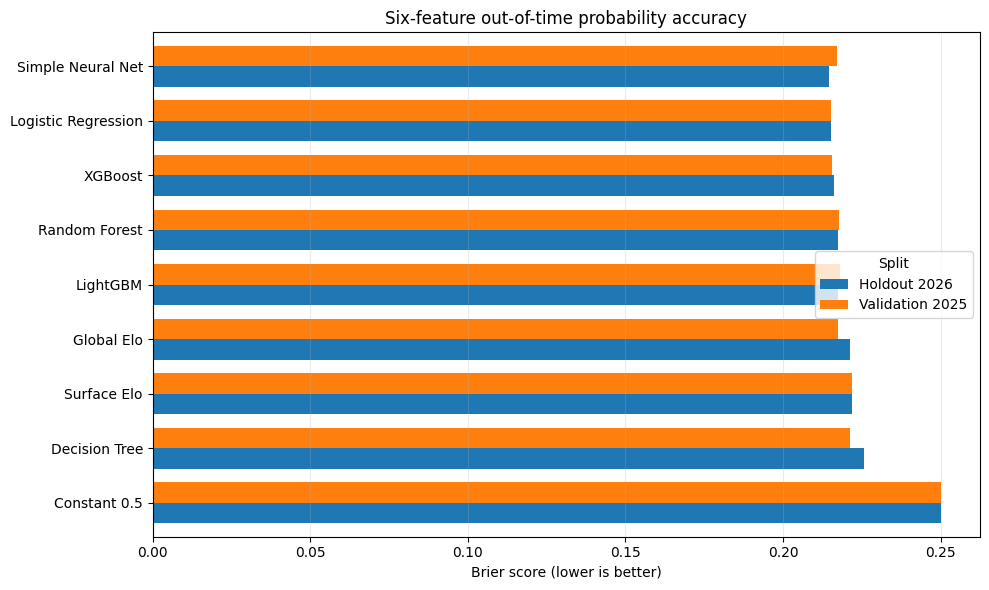

Best validation model: Logistic Regression (0.21516)
Best holdout model: Simple Neural Net (0.21462)
Saved evaluation and final Decision Tree pipelines.


Saved evaluation and final Random Forest pipelines.


Saved evaluation and final XGBoost pipelines.


/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Saved evaluation and final LightGBM pipelines.
Saved evaluation and final Logistic Regression pipelines.


Saved evaluation and final Simple Neural Net pipelines.
Saved research manifest to /Users/nick/Desktop/tennis live/research/models/model_manifest.csv
All evaluation and final Joblibs reloaded with exactly six features.
Research-only export boundary verified; deployment files were not touched.


,Model,FeatureCount,FeatureList,ValidationBrierScore,ValidationLogLoss,HoldoutBrierScore,HoldoutLogLoss,EvaluationArtifact,EvaluationTrainingStart,EvaluationTrainedThrough,HoldoutStart,HoldoutEnd,HoldoutRows,FinalArtifact,FinalTrainingStart,FinalTrainedThrough,FinalTrainingRows,FinalSizeMB
0,Simple Neural Net,6,GlobalEloDiff|SurfaceEloDiff|RankDiff|Player1L...,0.217016,0.621727,0.214618,0.616750,models/holdout_2026/simple_neural_net.joblib,2015-01-05,2025-11-16,2026-01-04,2026-08-14,1822,models/simple_neural_net.joblib,2015-01-05,2026-08-14,28425,0.061843
1,Logistic Regression,6,GlobalEloDiff|SurfaceEloDiff|RankDiff|Player1L...,0.215162,0.617846,0.215355,0.618070,models/holdout_2026/logistic_regression.joblib,2015-01-05,2025-11-16,2026-01-04,2026-08-14,1822,models/logistic_regression.joblib,2015-01-05,2026-08-14,28425,0.001604
2,XGBoost,6,GlobalEloDiff|SurfaceEloDiff|RankDiff|Player1L...,0.215613,0.620439,0.216206,0.620670,models/holdout_2026/xgboost.joblib,2015-01-05,2025-11-16,2026-01-04,2026-08-14,1822,models/xgboost.joblib,2015-01-05,2026-08-14,28425,0.151577
3,Random Forest,6,GlobalEloDiff|SurfaceEloDiff|RankDiff|Player1L...,0.217809,0.625443,0.217335,0.623148,models/holdout_2026/random_forest.joblib,2015-01-05,2025-11-16,2026-01-04,2026-08-14,1822,models/random_forest.joblib,2015-01-05,2026-08-14,28425,8.998455
4,LightGBM,6,GlobalEloDiff|SurfaceEloDiff|RankDiff|Player1L...,0.218124,0.627412,0.217552,0.624291,models/holdout_2026/lightgbm.joblib,2015-01-05,2025-11-16,2026-01-04,2026-08-14,1822,models/lightgbm.joblib,2015-01-05,2026-08-14,28425,0.557194
5,Decision Tree,6,GlobalEloDiff|SurfaceEloDiff|RankDiff|Player1L...,0.221178,0.662285,0.225548,0.701279,models/holdout_2026/decision_tree.joblib,2015-01-05,2025-11-16,2026-01-04,2026-08-14,1822,models/decision_tree.joblib,2015-01-05,2026-08-14,28425,0.011378


In [5]:
score_pivot = score_results.pivot(
    index="Method",
    columns="Split",
    values="BrierScore",
).sort_values("Holdout 2026", ascending=False)
ax = score_pivot.plot(kind="barh", figsize=(10, 6), width=0.75)
ax.set_title("Six-feature out-of-time probability accuracy")
ax.set_xlabel("Brier score (lower is better)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

best_validation_model = model_score_results.loc[
    model_score_results["Split"].eq("Validation 2025")
].nsmallest(1, "BrierScore").iloc[0]
best_holdout_model = model_score_results.loc[
    model_score_results["Split"].eq("Holdout 2026")
].nsmallest(1, "BrierScore").iloc[0]
print(
    f"Best validation model: {best_validation_model['Method']} "
    f"({best_validation_model['BrierScore']:.5f})"
)
print(
    f"Best holdout model: {best_holdout_model['Method']} "
    f"({best_holdout_model['BrierScore']:.5f})"
)

MODEL_DIR = RESEARCH_DIR / "models"
EVALUATION_MODEL_DIR = MODEL_DIR / "holdout_2026"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_MODEL_DIR.mkdir(parents=True, exist_ok=True)
assert MODEL_DIR.resolve().parent == RESEARCH_DIR.resolve()
assert EVALUATION_MODEL_DIR.resolve().parent == MODEL_DIR.resolve()

MODEL_FILENAMES = {
    "Decision Tree": "decision_tree.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib",
    "LightGBM": "lightgbm.joblib",
    "Logistic Regression": "logistic_regression.joblib",
    "Simple Neural Net": "simple_neural_net.joblib",
}

all_data = pd.concat(
    [datasets["Train"], datasets["Validation"], datasets["Holdout"]],
    ignore_index=True,
).sort_values("Date", kind="stable").reset_index(drop=True)
X_all = all_data[feature_columns].copy()
y_all = all_data[TARGET_COLUMN].astype("int8")
assert X_all.columns.tolist() == feature_columns
assert len(X_all) == sum(len(frame) for frame in datasets.values())

model_manifest_rows = []
verification_rows = min(1_000, len(X_all))
for model_name, filename in MODEL_FILENAMES.items():
    evaluation_path = EVALUATION_MODEL_DIR / filename
    evaluation_pipeline = evaluation_pipelines[model_name]
    assert list(evaluation_pipeline.feature_names_in_) == feature_columns
    joblib.dump(evaluation_pipeline, evaluation_path, compress=3)

    reloaded_evaluation = joblib.load(evaluation_path)
    assert list(reloaded_evaluation.feature_names_in_) == feature_columns
    reloaded_holdout_probabilities = positive_probability(
        reloaded_evaluation, X_holdout
    )
    assert np.allclose(
        reloaded_holdout_probabilities,
        holdout_predictions[model_name],
        rtol=1e-7,
        atol=1e-9,
    )

    final_pipeline = build_model_pipeline(model_name)
    final_pipeline.fit(X_all, y_all)
    assert list(final_pipeline.feature_names_in_) == feature_columns
    final_verification_probabilities = positive_probability(
        final_pipeline, X_all.iloc[:verification_rows]
    )

    final_path = MODEL_DIR / filename
    joblib.dump(final_pipeline, final_path, compress=3)
    reloaded_final = joblib.load(final_path)
    assert list(reloaded_final.feature_names_in_) == feature_columns
    reloaded_final_probabilities = positive_probability(
        reloaded_final, X_all.iloc[:verification_rows]
    )
    assert np.allclose(
        reloaded_final_probabilities,
        final_verification_probabilities,
        rtol=1e-7,
        atol=1e-9,
    )

    validation_row = model_score_results.loc[
        model_score_results["Split"].eq("Validation 2025")
        & model_score_results["Method"].eq(model_name)
    ].iloc[0]
    holdout_row = model_score_results.loc[
        model_score_results["Split"].eq("Holdout 2026")
        & model_score_results["Method"].eq(model_name)
    ].iloc[0]
    model_manifest_rows.append(
        {
            "Model": model_name,
            "FeatureCount": len(feature_columns),
            "FeatureList": "|".join(feature_columns),
            "ValidationBrierScore": validation_row["BrierScore"],
            "ValidationLogLoss": validation_row["LogLoss"],
            "HoldoutBrierScore": holdout_row["BrierScore"],
            "HoldoutLogLoss": holdout_row["LogLoss"],
            "EvaluationArtifact": str(evaluation_path.relative_to(RESEARCH_DIR)),
            "EvaluationTrainingStart": train_validation["Date"].min().date(),
            "EvaluationTrainedThrough": train_validation["Date"].max().date(),
            "HoldoutStart": datasets["Holdout"]["Date"].min().date(),
            "HoldoutEnd": datasets["Holdout"]["Date"].max().date(),
            "HoldoutRows": len(y_holdout),
            "FinalArtifact": str(final_path.relative_to(RESEARCH_DIR)),
            "FinalTrainingStart": all_data["Date"].min().date(),
            "FinalTrainedThrough": all_data["Date"].max().date(),
            "FinalTrainingRows": len(y_all),
            "FinalSizeMB": final_path.stat().st_size / (1024**2),
        }
    )
    print(f"Saved evaluation and final {model_name} pipelines.")

model_manifest = (
    pd.DataFrame(model_manifest_rows)
    .sort_values("HoldoutBrierScore")
    .reset_index(drop=True)
)
manifest_path = MODEL_DIR / "model_manifest.csv"
score_path = MODEL_DIR / "model_scores.csv"
odds_score_path = MODEL_DIR / "bookmaker_benchmark_scores.csv"
model_manifest.to_csv(manifest_path, index=False)
score_results.to_csv(score_path, index=False)
odds_benchmark_results.to_csv(odds_score_path, index=False)

assert model_manifest["FeatureCount"].eq(6).all()
assert model_manifest["FeatureList"].eq("|".join(feature_columns)).all()
assert all(
    path.resolve().is_relative_to(RESEARCH_DIR.resolve())
    for path in [MODEL_DIR, EVALUATION_MODEL_DIR, manifest_path, score_path, odds_score_path]
)
print(f"Saved research manifest to {manifest_path.resolve()}")
print("All evaluation and final Joblibs reloaded with exactly six features.")
print("Research-only export boundary verified; deployment files were not touched.")
model_manifest